# FYTA — Data Engineer assessment

Nine tasks, on the four source tables in `../data/`.

| | | |
|:---|:---|:---|
| **Task 1** | Ingest & orient — what the data **is** | 1a–1e |
| **Task 2** | Data quality — what is **wrong** with it | 2a–2c |
| **Task 3** | Cleaning — a first pass, with an audit before publishing | 3a |
| **Task 4** | Source agreement — do the four sources agree? | 4a |
| **Task 5** | Feature table — one time-indexed table per plant | 5a |
| **Task 6** | Triangulation — can three sources confirm one event? | 6a |
| **Task 7** | Pipeline design for 100k devices — sketch, not built | 7a–7g |
| **Tasks 8, 9** | Optional stretches — a signal, and log text | 8a, 9a |

Task numbers are the brief's; the letter is the section within that task, so
`3a` is the first section of Task 3. The same labels appear in the run log, so
`uv run fyta_pipeline.py` and this notebook read the same way.

**The split matters.** Task 1 describes what is there; Task 2 says what is wrong
with it. Where the two could overlap the rule is simple — Task 1 states the
contract, Task 2 reports the violations.

All the logic lives in the `fyta/` package (`domain`, `sensors`, `cleaning`,
`sources`, `features`, `signals`). This notebook imports it and shows the
results, so the code that produces the run log is the code you read here.


In [1]:
import pandas as pd

from fyta.cleaning import audit, clean
from fyta.domain import CADENCE, CHANNELS, IMPOSSIBLE, SPEC
from fyta.features import assert_grain, plant_features, plant_summary
from fyta.sensors import (
    COMPLIANCE_COLS, COVERAGE_COLS, FINDING_COLS, align_clocks,
    check_grid, detection_coverage_frame, device_coverage, evidence_tables,
    findings_frame, frozen_windows, key_uniqueness, parse_timestamps,
    plot_by_device, plot_fleet,
)
from fyta.signals import drydown_rate, log_signals
from fyta.sources import assess_source, image_predictions, triangulate
from fyta_pipeline import DATA, OUT

pd.set_option("display.width", 200)
print("data:", DATA.resolve())


data: /home/sagar/Projects/FYTA Assessment/data


---
# Task 1 — Ingest & orient

## 1a. Load

Two date formats exist. Seven devices write ISO (`2026-06-01 00:00:00`).
SENS-07 writes day-first (`01/06/2026 02:00`).

`parse_timestamps` handles both, and **stops on anything else**. Letting pandas
guess would be easier. A guess turns a format change into empty cells, and you
only find out weeks later — from a model that has quietly lost rows.


In [2]:
sensor = pd.read_csv(DATA / "fyta_sensor_sample.csv")
sensor["ts"] = parse_timestamps(sensor["timestamp"])
sensor = sensor.sort_values(["device_id", "ts"], ignore_index=True)

# one date format each, so pandas' own inference is safe here
contextual = pd.read_csv(DATA / "fyta_contextual.csv", parse_dates=["created_at"])
images     = pd.read_csv(DATA / "fyta_images.csv", parse_dates=["captured_at"])
mapping    = pd.read_csv(DATA / "user_plant_device_map.csv")

for name, df in [("sensor", sensor), ("contextual", contextual),
                 ("images", images), ("mapping", mapping)]:
    print(f"{name:11} {df.shape[0]:>6} rows x {df.shape[1]} cols")

fmt = (sensor["timestamp"].astype(str).str.match(r"^\d{4}-")
       .map({True: "ISO  YYYY-MM-DD", False: "DD/MM  DD/MM/YYYY"}))
print("\nsensor date formats:", fmt.value_counts().to_dict())

sensor       15950 rows x 9 cols
contextual      49 rows x 5 cols
images          28 rows x 5 cols
mapping          8 rows x 3 cols

sensor date formats: {'ISO  YYYY-MM-DD': 13934, 'DD/MM  DD/MM/YYYY': 2016}


**Nothing is changed.** This is easy to check, so it is checked: every column
holds exactly the same values before and after loading. Same 15,950 rows. No new
empty cells. One added column (`ts`).

Reading a date is not editing it. The file says `2026-06-01 00:00:00`, and that
text becomes a date so it can be used. No value moves.


In [3]:
raw = pd.read_csv(DATA / "fyta_sensor_sample.csv")
print("does ingest change any value? (order-independent multiset comparison)\n")
for c in raw.columns:
    same = raw[c].value_counts(dropna=False).sort_index().equals(
        sensor[c].value_counts(dropna=False).sort_index())
    print(f"  {c:20} unchanged: {same}")
print("\nrows dropped or added:", len(sensor) - len(raw))

does ingest change any value? (order-independent multiset comparison)

  device_id            unchanged: True
  timestamp            unchanged: True
  substrate_label      unchanged: True
  soil_moisture_vwc    unchanged: True
  soil_temp_c          unchanged: True
  ec_us_cm             unchanged: True
  light_par            unchanged: True
  air_humidity_pct     unchanged: True

rows dropped or added: 0


### The ambiguous date, settled with evidence

`01/06/2026` could be 1 June or 6 January. The obvious check — *"if I read it
wrong, the timestamps stop being 15 minutes apart"* — **does not work.** If
every row is misread the same way, the spacing never changes, and the grid still
looks 99% correct.

What settles it is **impossibility**: a month cannot be 13.


In [4]:
slash = sensor["timestamp"].astype(str).str.match(r"^\d{1,2}/")
dmy_text = sensor.loc[slash, "timestamp"].astype(str)
fields = dmy_text.str.extract(r"^(\d{1,2})/(\d{1,2})/(\d{4})").astype(int)

print(f"slash-dated rows      : {len(dmy_text)}")
print(f"first field range     : {fields[0].min()}..{fields[0].max()}")
print(f"impossible as a month : {int((fields[0] > 12).sum())} rows "
      f"({(fields[0] > 12).mean():.1%})  -> day-first is the only consistent reading")

slash-dated rows      : 2016
first field range     : 1..22
impossible as a month : 872 rows (43.3%)  -> day-first is the only consistent reading


## 1b. Structure

The entities, the declared grain of each table, and how much of the window each
device covers.

Facts only. Whether the grain actually *holds* is Task 2's question.


In [5]:
declared = [(name, df, keys) for name, df, keys in [
    ("sensor",     sensor,     ["device_id", "ts"]),
    ("contextual", contextual, ["log_id"]),
    ("images",     images,     ["image_id"]),
    ("mapping",    mapping,    ["device_id"]),
]]

print(f"sensors {mapping['device_id'].nunique()}   plants {mapping['user_plant_id'].nunique()}")
print(f"sensors per plant: {mapping.groupby('user_plant_id').size().to_dict()}\n")
key_uniqueness(declared)

sensors 8   plants 6
sensors per plant: {'UP-1001': 2, 'UP-1002': 1, 'UP-1003': 2, 'UP-1004': 1, 'UP-1005': 1, 'UP-1006': 1}



,table,declared_grain,unique
0,sensor,device_id+ts,False
1,contextual,log_id,True
2,images,image_id,True
3,mapping,device_id,True


In [6]:
# What each device covers, and how many readings it was due. The compliance
# columns (missing / surplus) are withheld here -- that is Task 2's report.
device_coverage(sensor, CADENCE)[COVERAGE_COLS]

,device,rows,slots_due,span_days,first,last
0,SENS-01,2016,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
1,SENS-02,2016,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
2,SENS-03,2016,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
3,SENS-04,2016,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
4,SENS-05,1823,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
5,SENS-06,2016,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00
6,SENS-07,2016,2016,20.99,2026-06-01 02:00:00,2026-06-22 01:45:00
7,SENS-08,2031,2016,20.99,2026-06-01 00:00:00,2026-06-21 23:45:00


## 1c. Channels, untouched

Raw, as delivered. Nothing filtered, including the readings that later turn out
to be impossible. Seeing them here uncorrected is the point.


In [7]:
sensor[CHANNELS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
soil_moisture_vwc,15950.0,29.36,12.55,-5.43,22.86,26.05,33.56,107.12
soil_temp_c,15950.0,27.16,16.46,16.10,18.85,21.77,24.10,78.01
ec_us_cm,15950.0,749.94,220.64,556.00,675.00,703.00,735.00,2266.00
light_par,15950.0,102.53,123.47,0.00,0.00,11.10,226.70,589.00
air_humidity_pct,15950.0,55.05,13.18,27.50,42.70,55.10,67.30,131.00


## 1d. Events and images

What the other three tables hold. 49 logs and 28 images, against 15,950 sensor
readings. The human and model data is very thin next to the sensor data.


In [8]:
print(f"log types        : {contextual['log_type'].value_counts().to_dict()}")
print(f"distinct texts   : {contextual['text'].nunique()} of {len(contextual)} rows")
print(f"images           : {len(images)}, hours {sorted(set(images['captured_at'].dt.hour))}")

log types        : {'watering': 34, 'light': 7, 'fertilising': 5, 'repotting': 3}
distinct texts   : 14 of 49 rows
images           : 28, hours [9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


## 1e. First look

A table hides shape. Two views: every channel across the fleet, then moisture
per device with the user's logs drawn on top.


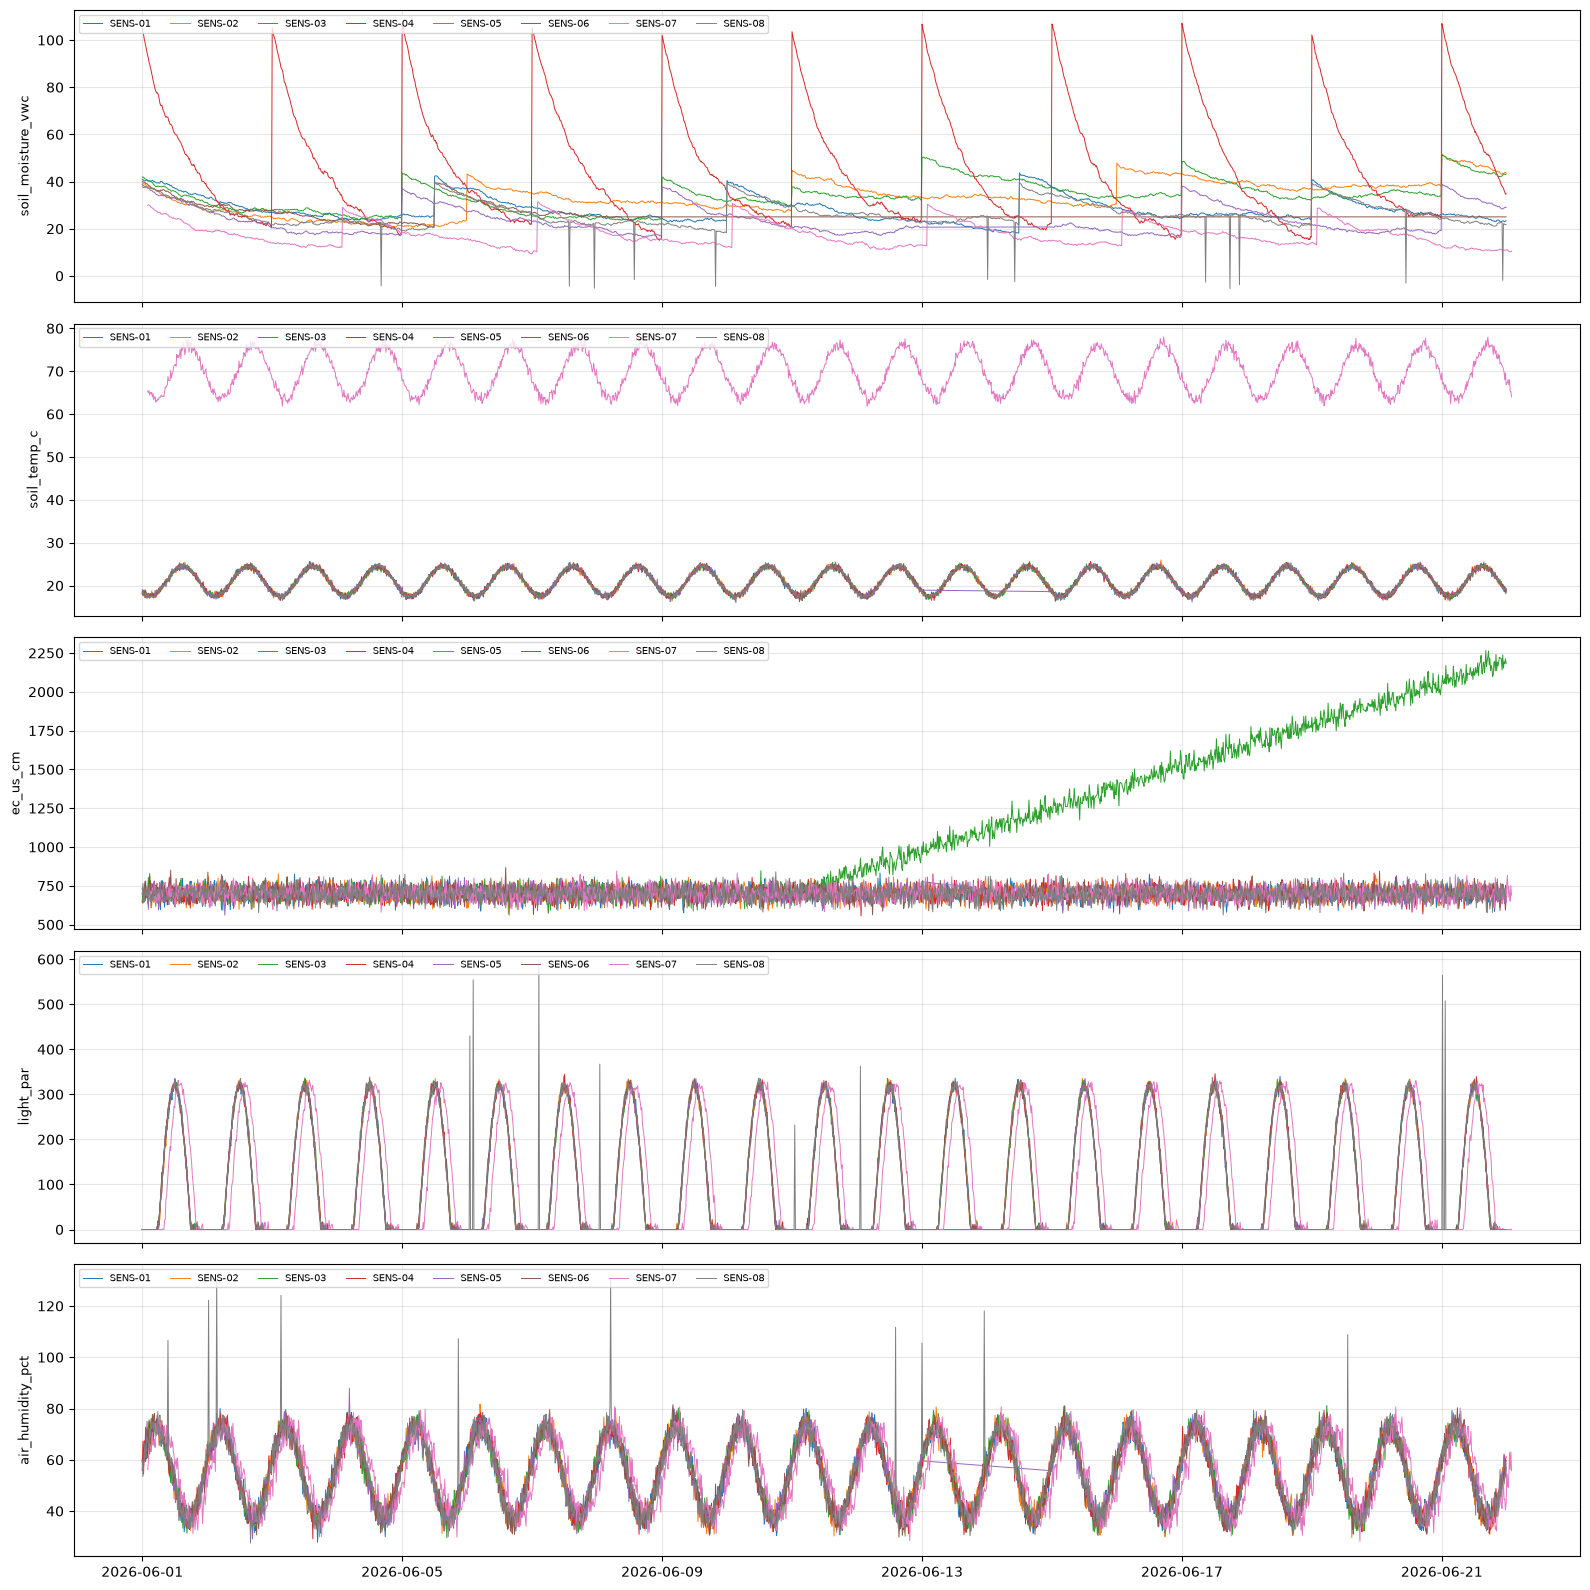

In [9]:
fleet = plot_fleet(sensor)
fleet.savefig(OUT / "figures" / "task1_fleet.png", dpi=75)
# the open figure renders inline when the cell finishes

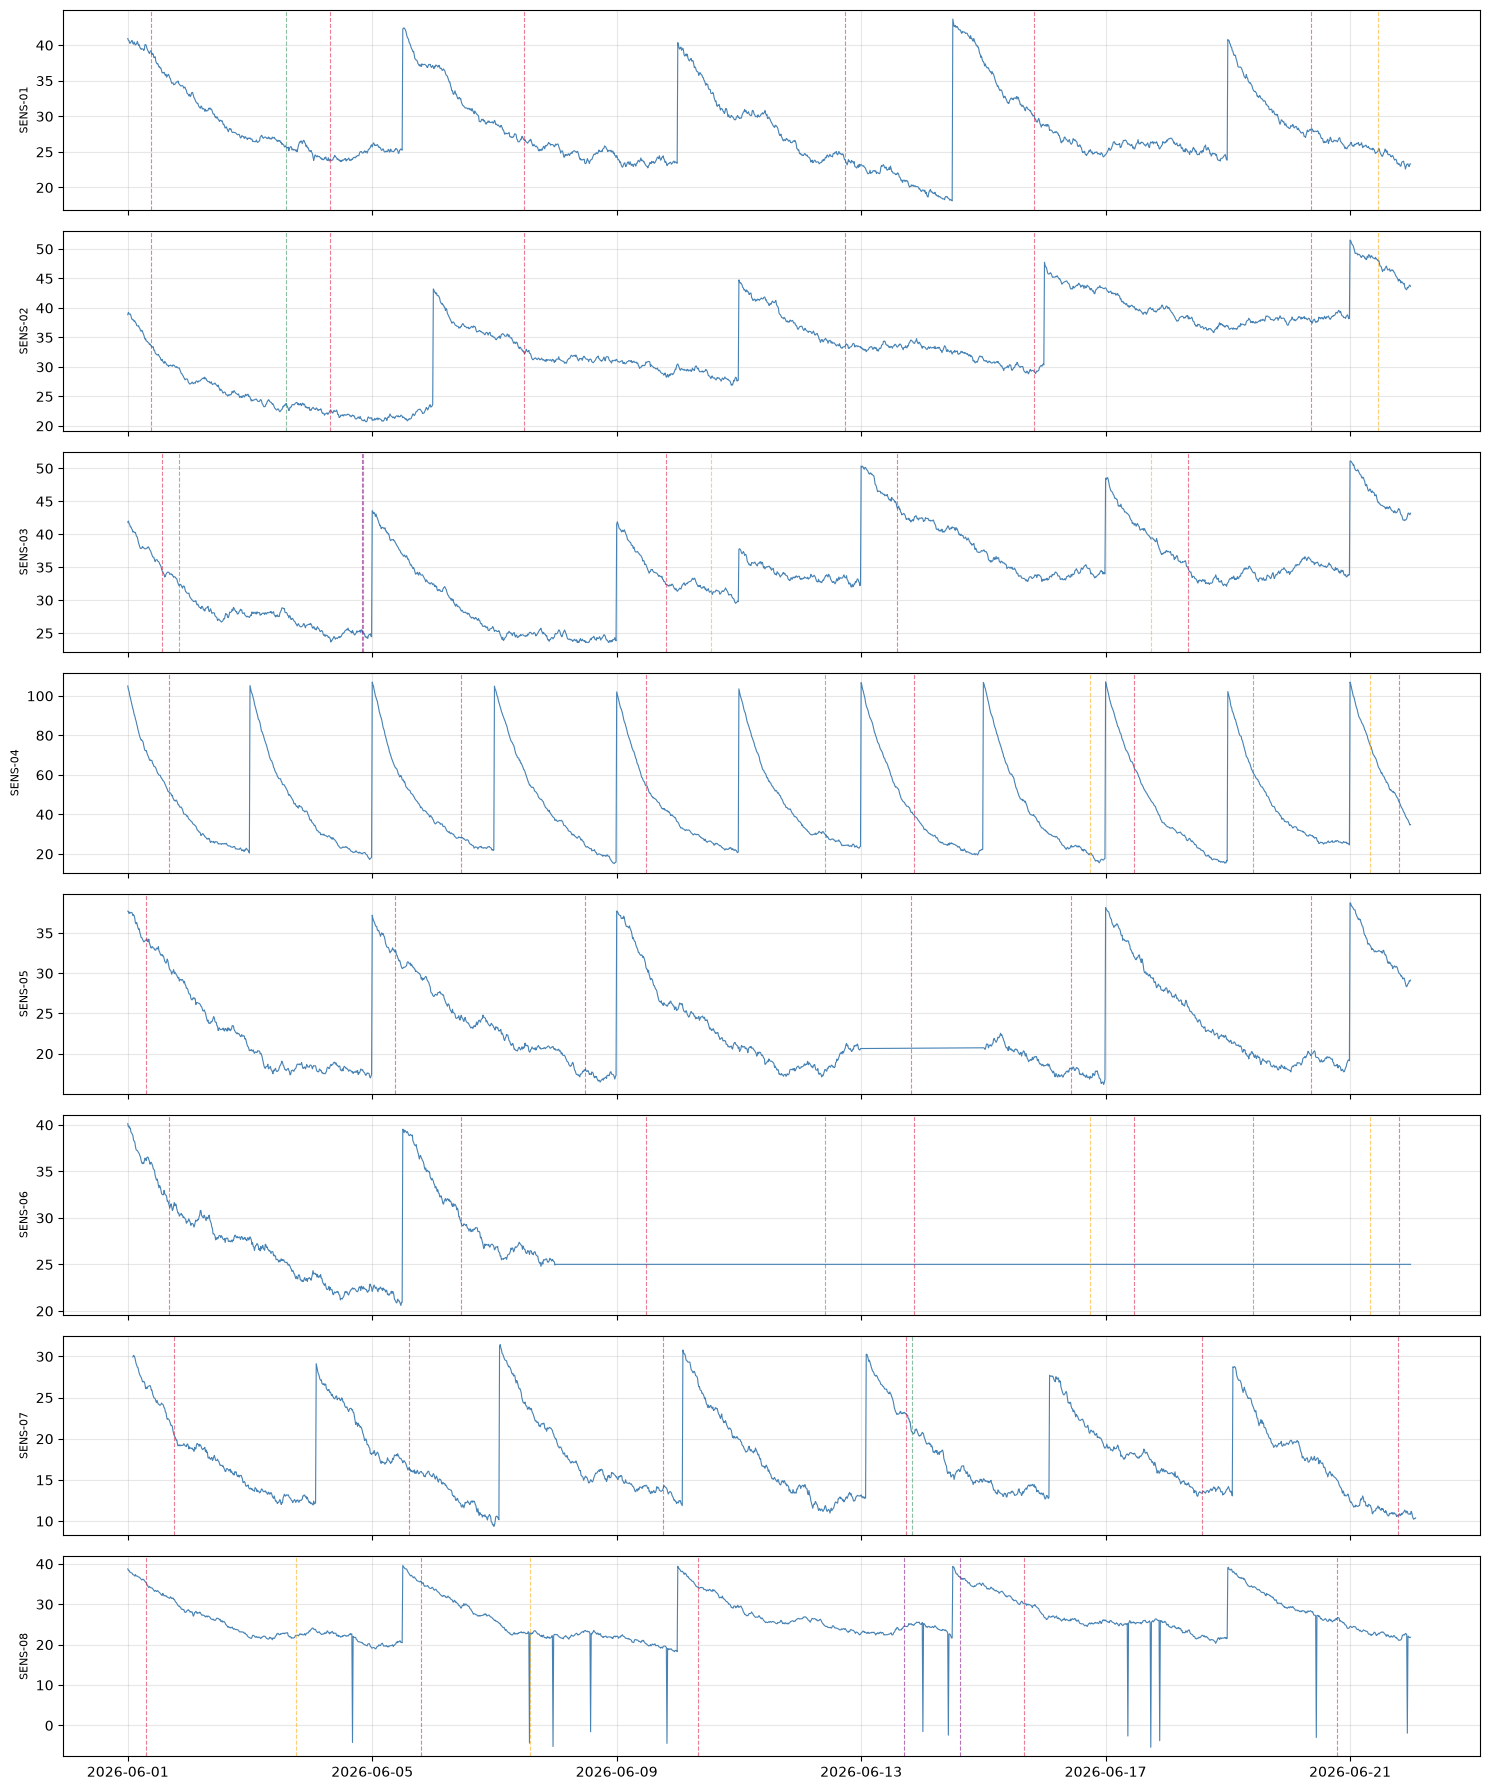

In [10]:
by_device = plot_by_device(sensor, mapping, contextual)
by_device.savefig(OUT / "figures" / "task1_by_device.png", dpi=75)

---
# Task 2 — Data quality

*"Find and characterize the problems. There are several, and they're of
different kinds. For each: what is it, how did you detect it, how serious is it,
and — importantly — is it a sensor/data problem or a real physical signal?"*

## 2a. Evidence

Ten checks, then the findings. The two are kept apart on purpose: seeing the
measurements before the verdicts means you can disagree with a verdict.

Each check asks a different question — value range, expected number of readings,
key uniqueness, join size, run length, agreement across channels, agreement
across devices, **and the device's own history**.

One distinction matters several times over.

**One bad reading is not the same as a long run of them.**

- A single impossible reading is a glitch. Empty it and move on.
- A long run of them is a real change. Empty those and you have deleted
  history, not cleaned it.

The same check reports both. Which one you have decides what to do.


In [11]:
import textwrap

from fyta.sensors import EVIDENCE_NOTES

# Every table carries its own one-line key, from the same source the run log
# uses -- so an output is readable without reading the code that produced it.
for title, frame in evidence_tables(sensor, mapping, contextual, images).items():
    print(f"\n=== {title} ===")
    print(textwrap.fill(EVIDENCE_NOTES.get(title, ""), 96,
                        initial_indent="    ", subsequent_indent="    "))
    print(frame.to_string(index=False))


=== declared grain violated ===
    rows sharing a key. Identical payloads are a redelivery; differing ones are unorderable.
    Both kept.
 rows_with_a_twin  superfluous  conflicting
               30           15            0

=== joins that multiply rows ===
    row count before and after joining each table to the mapping. A rise means the join key is
    not unique on the right.
fact_table       join_on  before  after  fans_out
contextual user_plant_id      49     67      True
    images user_plant_id      28     35      True
    sensor     device_id   15950  15950     False

=== coverage against the grid ===
    every slot each device was due, as delivered / missing / surplus. Row counts hide a device
    that is half-present.
 device  slots_due  delivered  missing  surplus  completeness  gaps     longest_gap
SENS-01       2016       2016        0        0        1.0000     0 0 days 00:15:00
SENS-02       2016       2016        0        0        1.0000     0 0 days 00:15:00
SENS-

## 2b. Findings

One table: every finding, with its severity, its class, the check that caught
it, and the check that would have missed it.

Severity and class are **judgements**. They are written apart from the evidence
so you can compare the two. Every number in the evidence tables above came out
of a check.


In [12]:
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 68)

findings = findings_frame()

# the two frames label findings differently; `id` is the shared key
covered = findings.merge(detection_coverage_frame().drop(columns=["finding"]),
                         on="id", how="left")

display(Markdown("**The findings** — with the check that caught each one, and "
                 "the check that is structurally blind to it"))
display(covered.set_index("id")[
    ["finding", "device", "severity", "class", "caught_by", "missed_by"]])

**The findings** — with the check that caught each one, and the check that is structurally blind to it

,finding,device,severity,class,caught_by,missed_by
id,,,,,,
F1,"SENS-07 soil_temp_c is Fahrenheit, not Celsius",SENS-07,high,data problem - unit error,jitter ratio = 1.8 (the F signature),"correlation -- affine-invariant, blind to scale"
F2,"SENS-07 on a +2h clock, and DD/MM while the fleet is ISO",SENS-07,high,data problem - clock/timezone,light cross-correlation vs peers,"cadence check -- grid is regular, just offset"
F3,SENS-06 moisture frozen at exactly 25.01 for 14 days,SENS-06,high,sensor fault - dead channel,run-length + cross-channel,range check -- 25.01 is a legal value
F4,"SENS-03 EC climbs monotonically, no logged cause",SENS-03,high,sensor fault - drift,early-vs-late median vs own noise,correlation -- EC has no shared signal
F5,SENS-04 moisture exceeds the instrument's specified 65% ceiling,SENS-04,high,unknown - fault or different physical setup,spec range + jitter + dry-down,null check -- the readings are present
F6,SENS-08 emits single-sample values that cannot be explained,SENS-08,low,22 sensor artefacts; 8 unresolved,range check; light spikes found by comparing against neighbours,run-length -- they are isolated samples
F7,SENS-05 missing 193 slots (48.5h),SENS-05,medium,data problem - availability,expected-slot grid,null count -- there are zero nulls
F8,SENS-08 has 15 superfluous duplicate rows,SENS-08,low,data problem - at-least-once redelivery,key cardinality,value checks -- the duplicates are all legal
F9,"user_plant_id is not unique, so log/image joins multiply rows",all,medium,schema problem,"join cardinality, before joining","value checks -- the data is fine, the key is not"


### What the classes mean

| Class | Findings | Where the fix belongs |
|:---|:---|:---|
| **data problem** | F1, F2, F7, F8 | Ingestion — a parser, a clock, a retry |
| **sensor fault** | F3, F4 | Hardware or calibration |
| **unknown** | F5, F10 | A measurement, or someone who can answer |
| **sensor artefact** | F6 | Cleaning — empty it, safely |
| **schema problem** | F9 | Modelling — fix the join |
| **label problem** | F11 | Label validation |
| **artefact** | F12 | Interpretation — it limits what you can test |
| **semantic** | F13 | Effective dating, from the app |

The two **unknown** entries are the honest ones. F5 could be a calibration
error, or just a different pot. F10 could be two real sensors, or a mapping
mistake. These files cannot tell the difference — so each one names the
measurement, or the person, who could.

Every threshold these findings depend on is recorded, with its owner, in
[`docs/decision_register.md`](../docs/decision_register.md).


### What caught it, and what would have missed it

Every problem in this dataset defeats at least one obvious check. That is what
makes it a trap rather than just a defect. It is also why the checks are
**different questions, not the same question repeated** — value range, expected
slots, key uniqueness, join size, run length, agreement across channels,
agreement across devices.

Three examples:

- **F2** — SENS-07's spacing is *perfect*. Every reading exactly 15 minutes
  apart. A schedule check says this device is fine. Only comparing it with its
  peers shows the shift.
- **F7** — there are **no empty cells anywhere** in the four files, yet 193
  readings are missing. The missing readings have no rows at all, so counting
  empty cells finds nothing.
- **F1** — SENS-07's temperature matches the fleet at **0.9843**, the highest
  score of any device, while it is actually in Fahrenheit. Correlation only
  measures whether two things move together. It cannot see a unit change.
- **F6** — **eight** light readings sit inside every stated limit. The brightest,
  589, is well within the sensor's rated 2000. They are wrong because of *when*
  they happened: a single 15-minute sample brighter than anything that device saw
  in daylight. No magnitude check can see that.

Repeating a check you already ran adds nothing. Only a new kind of question
finds a new kind of problem.


---
# Task 3 — Cleaning & normalization

*"Implement a first pass at turning this raw data into something a modelling
team could trust. Be explicit about what you handle, what you deliberately
leave, and why. Naïvely deleting or averaging away problems is usually the
wrong call."*

## 3a. Clean, then audit before publishing

**Raw data is never edited.** Every fix goes into a new column, and the original
stays next to it. Nothing is clipped, averaged or filled in.

**Two levels, not one.** "Outside the specified range" and "definitely wrong"
are different claims:

| Condition | Treatment |
|:---|:---|
| Physically impossible (moisture below 0, humidity above 100) | **empty it** — definitely wrong |
| Outside the specified range but possible (moisture 65–107) | **flag it, keep it** |

The device is not *specified* to be accurate above 65%. That is not the same as
the reading being wrong. Emptying those would delete 21% of SENS-04's readings —
and lose the shape that makes its drying cycle readable.

### How the "impossible" bounds were chosen

Two of the five are **definitional** — arithmetic, not judgement. A volume
fraction cannot exceed 100 %, and relative humidity is capped by definition.

The other three are **judgement calls, and deliberately wide**:

| Bound | Reasoning |
| :--- | :--- |
| `soil_temp_c` −30 … 70 °C | Potted soil. Below −30 it is frozen solid; above 70 it would kill the plant, so it is not a soil temperature. Wide enough that an outdoor pot in a Berlin winter cannot trip it |
| `ec_us_cm` 0 … 20 000 µS/cm | ~12× the published ceiling, and about 40 % of seawater |
| `light_par` 0 … 2 500 µmol | Full summer sun is ~2000–2200. 2500 is *brighter than the sun* |

**The asymmetry decides the width.** A bound too narrow **nulls real data** —
destructive and unrecoverable in the published table. A bound too wide merely
leaves junk *flagged*, which is visible and reversible. So the impossible ceiling
sits well above the specified ceiling (1.25× to 12×), and the flag band does the
work in between.

**They are deliberately not derived from the data.** A quantile cut or a "3σ from
the fleet mean" rule moves with the data, so a fleet-wide fault would shift the
bound and hide inside it. A fixed physical limit cannot.

**Order matters as much as the bound.** `soil_temp_c` is checked *after* the
Fahrenheit conversion — checked before it, SENS-07's 61.9–78.0 °F looks like
62–78 °C and **982 good readings would be nulled**.

**All three rest on a conversation** — D1, are the published ranges current for
this hardware generation? They are set generously so a wrong answer is
survivable, but hardware can settle them properly.


In [13]:
windows = frozen_windows(sensor)
cleaned, rejections = clean(sensor, windows)

print(f"rows in            : {len(sensor)}")
print(f"duplicates dropped : {int(sensor.duplicated(['device_id', 'ts']).sum())}")
print(f"rows out           : {len(cleaned)}")
print(f"values nulled      : {len(rejections)}")
print(f"values flagged     : {int((cleaned['qc_flags'] != '').sum())}  (kept, marked out of spec)")
print()
print(rejections["reason"].str.split(" (", regex=False).str[0].value_counts().to_string())

rows in            : 15950
duplicates dropped : 15
rows out           : 15935
values nulled      : 1415
values flagged     : 744  (kept, marked out of spec)

reason
frozen_channel    1344
impossible          71


In [14]:
print("raw vs cleaned, the channels that changed:\n")
for channel in CHANNELS:
    r, c = sensor[channel], cleaned[f"{channel}_clean"]
    print(f"{channel:18} raw [{r.min():8.2f}, {r.max():8.2f}]   "
          f"clean [{c.min():8.2f}, {c.max():8.2f}]   nulls {int(c.isna().sum())}")

raw vs cleaned, the channels that changed:

soil_moisture_vwc  raw [   -5.43,   107.12]   clean [    9.36,    99.95]   nulls 1405
soil_temp_c        raw [   16.10,    78.01]   clean [   16.10,    25.97]   nulls 0
ec_us_cm           raw [  556.00,  2266.00]   clean [  556.00,  2266.00]   nulls 0
light_par          raw [    0.00,   589.00]   clean [    0.00,   589.00]   nulls 0
air_humidity_pct   raw [   27.50,   131.00]   clean [   27.50,    87.90]   nulls 10


### Audit before publishing

Nothing reaches a reader until it passes. Each row below is a claim the cleaning
step makes about itself.


In [15]:
audit(cleaned, sensor, rejections)

,check,passed,detail
0,no duplicate keys remain,True,15 dropped
1,soil_moisture_vwc: no impossible values left,True,0 remain
2,soil_temp_c: no impossible values left,True,0 remain
3,ec_us_cm: no impossible values left,True,0 remain
4,light_par: no impossible values left,True,0 remain
5,air_humidity_pct: no impossible values left,True,0 remain
6,raw columns untouched,True,all 5 raw channels match the source
7,every rejection is null in its clean column,True,0 of 1415 rejections still hold a value
8,every null has a rejection behind it,True,unexplained: none
9,soil_moisture_vwc: outside_spec flags match the detector,True,"382 detected -- 0 unflagged, 0 flagged but in range"


### What was deliberately left alone

| Finding | Why it is not a cleaning job |
|:---|:---|
| **F4** SENS-03 EC drift | Dropping a channel is a *modelling* decision, not a data fix. Flagged in `qc_flags`, values kept |
| **F7** the 48.5h outage | Left as a hole. Filling it would invent 193 readings that were never taken |
| **F9** the join multiplying rows | A schema problem — fixed at the join, not in the data |
| **F10** two sensors on one plant | Unresolved. Averaging them would produce a number that describes neither pot |
| **F11** logs not matching the sensor | A label problem. The sensor readings are not wrong |
| **F12** shared environment | A limit on what can be tested, not a defect |
| **F13** substrate label | Needs dating from the app; the data cannot supply it |

**Nothing was clipped to range, averaged, or filled in.** All three would have
invented measurements that were never taken.

### Output

| File | Rows | What it is |
|:---|:---|:---|
| `out/cleaned_sensor.csv` | 15,935 | Raw columns + `ts_aligned` + five `_clean` columns + `qc_flags` |
| `out/qc_rejections.csv` | 1,415 | Every removed value, with its reason |
| `out/task2_findings.csv` | 13 | The findings table |


## 3b. Normalize — the image table

*"Turning this raw data into something a modelling team could trust."*

The sensor table needed **cleaning** — values corrected, holes recorded. The image
table needs **normalizing**: nothing is wrong with it, but `prediction` is a JSON
blob in one column, which no consumer can filter, join or aggregate.

Flattening it is the same job in a different guise — turn what was delivered into
what can be used.

| | |
|:---|:---|
| **In** | 28 rows, one JSON blob each |
| **Out** | 28 rows, one column per head |
| **Also derived** | the parent→child hierarchy, read from each head's own `classification` chain |

The hierarchy is read rather than transcribed so a model version that renames or
re-parents a class needs no code edit. `nutrient-related issue` is why it matters:
it appears as a classification but is **never scored** — a label *on* the
taxonomy, not a class *in* it.

**The CSV is for consumers.** The pipeline still parses `data/fyta_images.csv`
directly. Reading back a file this pipeline wrote would make it depend on its own
history, and a stale copy would go unnoticed.


In [16]:
heads, head_cols, children = image_predictions(images)

# The check for the parse. The first version of the hierarchy took chain[-1] as
# the parent, and `nutrient-related issue` is a label on the taxonomy rather than
# a class in it -- so it named a parent with no column.
assert all(p in head_cols for p in children), \
    f"hierarchy names a parent that is not a head: {set(children) - set(head_cols)}"
assert set(head_cols) >= set(sum(children.values(), [])), \
    "a child is missing from the head columns"

print(f"rows in  : {len(images)}   (one JSON blob each)")
print(f"rows out : {len(heads)}   (one column per head)")
print(f"heads    : {len(head_cols)}")
for parent, kids in children.items():
    print(f"  {parent:22} <- {', '.join(kids)}")

heads.to_csv(OUT / "images_flattened.csv", index=False)
print("\npublished: images_flattened.csv")

rows in  : 28   (one JSON blob each)
rows out : 28   (one column per head)
heads    : 7
  Abiotic                <- Nutrient deficiency, Water-related issue
  Water-related issue    <- Water deficiency, Water excess and/or uneven watering

published: images_flattened.csv


---
# Task 4 — Do the four sources agree?

*"Does the image model's prediction agree with what the sensors say? Do labels
agree across plant species, contextual logs, image predictions and sensor data?"*

Only the sensors **measure** anything. The other three are reports *about* the
plant — so the question is what each can be checked against, and what it cannot.


### The answers

| Source | Question | Answer |
|:---|:---|:---|
| **Plant species** | • Is one substrate used per species? | ✅ |
| | • Can it be checked against a date? | ❌ never changes (F13) |
| | | |
| **Contextual logs** | • Is there one `log_type` per phrase? | ⚠️ 14 phrases, **zero ambiguous** — consistent, and suspiciously so |
| | • Do the logs line up with the sensors? | ❌ **no — all four types tested, none lines up, and light CONTRADICTS** (F11) |
| | | |
| **Image predictions** | • Is it internally consistent? | ✅ `is_healthy` is exactly `p > 0.5` |
| | • Does it agree with the sensors? | ⚠️ **yes on water, r = 0.75** — independence unestablished |
| | • Do the independent heads ever fire? | ❌ `Fungi` / `Animalia` never exceed 0.06 |
| | | |
| **Sensor data** | • The reference the other three are read against | its own defects are Tasks 1–3 |


### Why :

- **Species** — static, so it can never be checked against a date.
- **Logs** — consistent *and* unrelated. **All four log types were tested against
  the channel their own event should move: none lines up, and one contradicts** —
  *"moved closer to window"* moves the daily light peak **down** (−4.4, n=3), the
  opposite of what it claims. The consistency is not a compliment either: a user
  typing freely eventually writes *"watered and fed"*, and none of the 49 do.
- **Images** — one moving signal, and it is water. Whether agreeing with the probe
  makes it *independent* is unverifiable here — the dataset is synthetic, so one
  generator could have emitted both.
- **Sensors** — the reference.

### The two things that would change the answer

| Question | What settles it | Owner |
|:---|:---|:---|
| Is the image model independent, or does one generator emit both? | Model lineage — did the model consume VWC? | Vendor |
| Are the logs real events, or generated? | Does the app offer canned phrases? | Product |

### Verdict

**A feature, never a label.** `is_healthy` is withheld — it is exactly
`probability > 0.5`. **Gate at ingestion:** pin `model_version`, fail on an
unknown head name.


---
# Task 5 — Unified per-plant feature table

*"Build a single time-indexed table per user_plant_id."*

## 5a. One table, one grain

Grain is `(user_plant_id, ts_aligned)` — declared **and asserted**, because a
table whose grain is assumed is a table whose numbers cannot be trusted.

### Two decisions that shape it

**Never average the probes.** UP-1001 and UP-1003 carry two devices each (F10).
Averaging them would invent a moisture value describing neither pot — and would
throw away the disagreement, which is the *entire reason* a second probe exists.
Both are kept, side by side, with `vwc_delta` as the gap between them.

**Rank within the device, over a trailing window.** VWC is only comparable
inside a substrate, so `vwc_pct_*` is the reading's rank in that probe's own
recent range — which is what makes it comparable *across* plants. The window is
trailing on purpose: ranking over the whole window would judge a day-1 reading
against day-21 data, which is leakage the moment this table feeds a model.


In [17]:
features = plant_features(cleaned, mapping)
rows = assert_grain(features)

print(f"grain   : (user_plant_id, ts_aligned) -- asserted, 0 duplicate keys")
print(f"rows    : {rows:,}    columns: {len(features.columns)}    "
      f"plants: {features['user_plant_id'].nunique()}")
print()
plant_summary(features)

grain   : (user_plant_id, ts_aligned) -- asserted, 0 duplicate keys
rows    : 11,903    columns: 23    plants: 6



,,rows,missing,probes,probes_filled,longest_gap_h
user_plant_id,species,,,,,
UP-1001,Monstera deliciosa,2016,0,2,1.000,0.2
UP-1002,Ficus lyrata,2016,0,1,1.000,0.2
UP-1003,Zamioculcas zamiifolia,2016,0,2,0.324,0.2
UP-1004,Basil (indoor),1823,193,1,1.000,48.5
UP-1005,Phalaenopsis orchid,2016,0,1,1.000,0.2
UP-1006,Pothos,2016,0,1,0.994,0.2


In [18]:
features[["user_plant_id", "species", "ts_aligned", "device_1", "device_2",
          "vwc_1", "vwc_2", "vwc_delta", "vwc_pct_1", "gap_minutes"]].head(4)

,user_plant_id,species,ts_aligned,device_1,device_2,vwc_1,vwc_2,vwc_delta,vwc_pct_1,gap_minutes
0,UP-1001,Monstera deliciosa,2026-06-01 00:00:00,SENS-01,SENS-02,40.93,38.86,2.07,NaN,NaN
1,UP-1001,Monstera deliciosa,2026-06-01 00:15:00,SENS-01,SENS-02,40.68,39.26,1.42,NaN,15.0
2,UP-1001,Monstera deliciosa,2026-06-01 00:30:00,SENS-01,SENS-02,40.63,39.0,1.63,NaN,15.0
3,UP-1001,Monstera deliciosa,2026-06-01 00:45:00,SENS-01,SENS-02,40.29,38.93,1.36,NaN,15.0


### Scope — what "unified" means here

This table unifies the **cleaned sensor channels and the plant metadata**. It
deliberately does **not** join in the logs or the images.

There are 49 log rows and 28 photos against 11,903 fifteen-minute rows. Spreading
a log across every row in its neighbourhood would duplicate it hundreds of times
and turn a sparse event into a claim about every slot; a photo the model evaluates
once cannot be sampled at 15-minute resolution. Production consumers should join
both **as-of**, with an explicit tolerance, and treat "no recent log" as a
different state from "no log".

That is a modelling decision, and this table does not silently make it.

### What the table does not hide

| | |
|:---|:---|
| **F10** | UP-1003's two probes disagree by **19.9% VWC** on average (n=653); UP-1001's by **8.8%** (n=2016). Both pots nominally hold one plant. `vwc_delta` separates "two probes in one pot" from "one probe is broken" — without it, both look like one number |
| **F3** | SENS-06's probe still contributes: when its channel froze it was nulled, so `vwc_delta` goes null for those 1,344 slots rather than silently reading as agreement |
| **F7** | UP-1004's longest gap is **48.5 hours** — the outage is an absent row plus a `gap_minutes` flag, not fabricated data |
| **F13** | `substrate` is what the app says *today*. With no effective dating, a repot mid-window is invisible. Do not read the column as "true at this timestamp" |

**If you want the probes fused, that is a modelling decision, not a data one.**
The table hands over both readings and their disagreement; picking the rule is
D11's conversation.


---
# Task 6 — Can a feature triangulation occur?

*"A log type fertilizing log should produce a rise in ec_us_cm data and the image
prediction return 'Nutrient deficiency'."*

## 6a. Three legs, and only one of them is present

| Leg | Should show | Does it? |
|:---|:---|:---|
| **The log** | fertiliser was added | ✅ 5 events |
| **The sensor** | EC rises | ❌ `dEC` sits inside one step of that device's own noise, and 2 of 5 are **negative** |
| **The model** | `Nutrient deficiency` responds | ❌ never exceeds 0.073 on any photo (4a) |

**Short answer: no — and not because the effect is weak.** Two of the three legs
carry no fertiliser signal at all. A head that never fires can neither agree nor
disagree.

Each row below is one fertilising event, with all three legs on it. The window
is 24 hours either side.


In [19]:
tri = triangulate(cleaned, features, contextual, heads)
shown = tri.assign(fertilised=tri["fertilised"].dt.strftime("%m-%d %H:%M"),
                   image=tri["image"].dt.strftime("%m-%d %H:%M"))
(shown[["log", "plant", "fertilised", "d_ec", "noise_sd", "d_ec_sigma",
        "image", "hours_off", "nutrient_def", "sensor_leg", "model_leg"]]
 .round(3))

,log,plant,fertilised,d_ec,noise_sd,d_ec_sigma,image,hours_off,nutrient_def,sensor_leg,model_leg
0,LOG-00001,UP-1001,06-03 14:00,3.198,57.245,0.06,06-04 16:30,26.5,0.050,no rise,silent
1,LOG-00009,UP-1002,06-01 20:00,3.974,58.114,0.07,NaN,NaN,NaN,no rise,no post-event image
2,LOG-00020,UP-1003,06-12 10:00,0.604,58.493,0.01,06-14 10:00,48.0,0.033,no rise,silent
3,LOG-00024,UP-1003,06-19 10:00,-3.115,58.493,-0.05,06-20 13:00,27.0,0.002,no rise,silent
4,LOG-00037,UP-1005,06-13 20:00,-6.010,57.024,-0.11,NaN,NaN,NaN,no rise,no post-event image


### The window is the trap

Widen the window and **UP-1002 appears to confirm**. Its EC climbs 1,289 µS/cm
across the record, so *"fertilised, then EC rose"* looks true.

It is not true. The climb **starts ten days after the feed** and is a straight
line — SENS-03's gain drift (F4), not chemistry. A separate defect sitting on the
same plant is what makes the false positive convincing.

| UP-1002, one fertilising log | 24 h window | whole record |
|:---|:---|:---|
| `dEC` | +4 µS/cm | **+1,289 µS/cm** |
| against the device's step noise | **0.07σ** | — |
| reading | flat | *looks* like a response |

Same data, two answers. The window is a modelling decision, and this is the one
place where it changes the conclusion.

### What would make triangulation work

All three of these, because two were never available here:

1. **A log that is timestamped when it happened.** Right now the logs do not line
   up with the sensor at all (F11) — the sensor's own rises land on the hour, the
   logs at human times
2. **An EC channel without drift.** SENS-03's ramp is larger than any feed effect
   and starts at an arbitrary date, so it has to be removed before EC can be read
   as chemistry
3. **A model head that fires.** `Nutrient deficiency` never exceeds 0.073, so it
   cannot corroborate or contradict. That is D-firmware's and D-hardware's
   question, not a modelling choice


---
# Task 7 — Pipeline design for 100,000+ devices

*"Sketch, don't build. How would you productionize this as an ingestion + quality
pipeline? What would you monitor, where would bad data get caught, and how would
you make the checks maintainable as new substrates and sensors appear?"*

## 7a. Size it first

Everything below follows from this, so it goes first. Computed in the cell
beneath rather than estimated.

| | |
|:---|:---|
| Devices | 100,000 |
| Readings/day | 100,000 × 96 = **9,600,000** |
| Average rate | **111 msg/s** |
| Messages/month | **288 M** |
| Row size (measured: file bytes / rows) | **67.9 B** |
| **Raw arrival** | **0.65 GB/day · 238 GB/year** |
| Parquet + zstd (measured **7.6×**) | **0.086 GB/day · 31 GB/year** |
| Published table, raw + cleaned side by side | 119 B/row · 0.17 GB/day |

The published table is ~2× the arrival volume, because it keeps the raw column
beside every cleaned one — the price of never destroying the original, and at
this scale still nothing. Every figure measured, not estimated.

**This is not big data.** 111 msg/s is a single process; 220 GB/year fits on a
laptop. Any design leading with Spark, a data mesh or "web-scale streaming" is
solving a problem this fleet does not have.

The real difficulties are the ones this assessment is about:

1. **100,000 things that can each be individually wrong** — a fleet average looks
   perfect while 300 devices are dead
2. **Data arrives late and out of order** — see below
3. **The semantics are hard** — substrate curves, unit errors, drift, artefacts
   vs signal. The checks are the product, not the plumbing

### The constraint that shapes everything

**The Beam is BLE.** It cannot reach the internet on its own, so ingestion is
relayed — phone app or hub. Uploads are bursty and human-scheduled.

**The buffer bounds the lateness, and the figure is conditional.** ~320
measurements per device; *if* the deployed generation buffers 320 readings at
four per hour, that is **up to ~80 hours**. FYTA's published figures separate
Beam 1.0 (1/hour) from Beam 2.0 (4/hour), and describe the 320-reading store as
~13 days — which matches 1/hour. **Confirm generation-specific storage with
firmware.**

> **Partition by event time, not arrival time.** Late arrival is *normal*, not
> exceptional — hours at least, days if the buffer is deeper. Late writes must
> replay and re-audit the *affected* partition, not append to today's.

This is the constraint most likely to be got wrong, and it comes from the
hardware spec rather than from the data volume.


In [20]:
N = 100_000
per_day = N * 96
# Measured from the shipped sample, not assumed: file bytes / data rows.
sample = DATA / "fyta_sensor_sample.csv"
rows_in_sample = sum(1 for _ in sample.open()) - 1          # minus the header
row_b = sample.stat().st_size / rows_in_sample
ZSTD = 7.57                                                 # measured Parquet+zstd ratio

print(f"readings/day    {per_day:,}")
print(f"average rate    {per_day / 86400:,.1f} msg/s")
print(f"messages/month  {per_day * 30 / 1e6:,.1f} M")
print(f"row size        {row_b:.1f} B   (measured: {rows_in_sample:,} rows in "
      f"{sample.stat().st_size / 1e6:.2f} MB)")
print(f"raw arrival     {per_day * row_b / 1e9:.2f} GB/day   {per_day * row_b * 365 / 1e9:.0f} GB/year")
print(f"parquet + zstd  {per_day * row_b / ZSTD / 1e9:.3f} GB/day   "
      f"{per_day * row_b * 365 / ZSTD / 1e9:.0f} GB/year   ({ZSTD}x measured)")

readings/day    9,600,000
average rate    111.1 msg/s
messages/month  288.0 M
row size        67.9 B   (measured: 15,950 rows in 1.08 MB)
raw arrival     0.65 GB/day   238 GB/year
parquet + zstd  0.086 GB/day   31 GB/year   (7.57x measured)


## 7b. Two variants, one shape

Both diagrams are the **same pipeline**. They differ only in what each box is made
of — a build-vs-buy question, not an architecture question.

**Variant A — self-hosted / OSS**

![Variant A](out/figures/task7_variant_a.jpeg)

**Variant B — AWS managed**

![Variant B](out/figures/task7_variant_b.jpeg)

| Concern | Variant A | Variant B |
|:---|:---|:---|
| Ingest | Redpanda | **AWS IoT Core + Basic Ingest** |
| Lake | MinIO | **Amazon S3** |
| Transform | dbt on DuckDB | dbt on DuckDB/Lambda or Athena |
| Serve | Postgres · Grafana · Metabase | RDS Postgres · Managed Grafana · QuickSight |
| Model | MLflow | SageMaker |
| Orchestration | Airflow | Step Functions |
| Ops | **Ops Agent on the box** | *(none — managed services absorb it)* |
| Optional | — | Kinesis, for sub-minute alerting |

**The cost lever worth knowing:** IoT Core's **Basic Ingest is free.** Publishing to
the reserved topic `$aws/rules/…` means you pay rules + actions only — messaging
drops from $288/month to **$0**.

And at this volume you can **skip the broker entirely**: `IoT Core rule → S3 →
batch-validate the new partition` is seconds of DuckDB. A broker earns its place
only when something must react *per message*.

## 7c. The decision rule

**Volume does not decide this.** 0.6 GB/day runs on a laptop, so the choice is
**total cost of ownership**:

| | Variant A | Variant B |
|:---|:---|:---|
| Infrastructure | €150–400/mo | ~$200–500/mo |
| **Operational load** | five services to patch, upgrade and be paged for — **~0.3–0.5 FTE** | ~0.05 FTE |
| Lock-in | none | IoT Core rules, Kinesis, QuickSight |
| Marginal cost at 10× | flat | linear |

0.3 FTE ≈ **€2,100/month** at loaded engineer cost — **10–20× the infrastructure
difference**.

> **Managed wins, and it is not close, because the scarce resource is the
> engineer, not the euro.**

**Flip to Variant A when:** 10× the fleet (1M devices → $860–3,450/mo on IoT Core
connectivity alone) · a residency or on-prem contract · a team already running k8s
competently · vendor repricing.

**And the point that makes them not really rivals:** the checks are Python and SQL
over Parquet, so they run on MinIO + DuckDB exactly as they run on S3 + Athena.
**Design the exit on day one**, and the substrate becomes a deployment detail
rather than a rewrite.


## 7d. Where bad data gets caught

Six layers, cheapest first. A check belongs in the earliest layer that can hold it.

| # | Layer | Catches |
|:---|:---|:---|
| 1 | **Firmware** | impossible readings, before transmission |
| 2 | **Ingest** | malformed payload, unknown device, **unknown substrate** |
| 3 | **Stream / per-reading** | out-of-range, impossible, duplicate keys |
| 4 | **Batch / per-device window** | frozen channel, **slot-grid gaps**, drift, clock offset, unit outliers, co-located disagreement |
| 5 | **Publish gate** | nothing reaches a consumer unless every check passed |
| 6 | **Post-publish monitoring** | what the gates missed |

**Layer 4 is where this assessment's findings live.** Every one of the 13 is a
per-device-window question that a per-row check structurally cannot see:

| Finding | Why a per-row check is blind |
|:---|:---|
| F3 frozen channel | every value is **in range**, and constant |
| F7 the 48.5 h hole | the file has **zero nulls** — only the expected-slot grid shows it |
| F2 clock offset | a **well-formed** timestamp that is two hours wrong |
| F12 shared ambient | the reading is correct; the *comparison* was the error |

## 7e. What to monitor

Per device, always — a fleet average hides exactly the failures you are looking for.

**Freshness · Volume · Schema · Distribution** — plus two that matter
disproportionately for a fleet:

- **Slot-grid completeness** — account for every slot the device *should* have
  produced, as present / missing / surplus. A device at 60 % present looks fine
  on row counts
- **Frozen-channel detection** — zero variance over a rolling window **while the
  same device's other channels keep moving**. The cross-channel comparison is
  what separates a dead sensor from a genuine plateau

Alerts must not flap: require the condition to persist, and use **different
thresholds to raise and to clear**.

## 7f. Keeping the checks maintainable

The part that decays, and the brief asks about it directly. Four mechanisms, in
order of importance.

**1. One declarative registry.** `substrate → curve version and expected band`,
`sensor family → channels/units/cadence/ranges`, `device → family/substrate/offset`.
A new substrate is a **row**, not a deploy; an unrecognised sensor family **fails
loudly**. The registry contains no I/O — domain knowledge must not know that CSVs
exist.

**2. Every check declares what it is blind to.** This is the mechanism that keeps
coverage honest, and it is already in this submission as
`task2_detection_coverage.csv`. Without it, adding checks creates the *feeling* of
coverage; with it, the gap is visible and the next check aims at a real blind spot
instead of another angle on something already covered.

**3. Detection ≠ remediation**, reconciled in both directions. A detector with no
fix is a warning nobody acts on; a fix with no detector silently rots.

**4. Regression fixtures** — a known-bad window per failure class, replayed on
every change, asserting each is still caught.


## 7g. What I would ask FYTA

The design forks on these, and none can be answered from the data.

| # | Question | Why it changes the design |
|:---|:---|:---|
| 1 | **Is there a hub/gateway, or does the phone relay?** | Sets the burst size, the lateness bound, and whether IoT Core connectivity is billable at all |
| 2 | **Minutes or hours to a dashboard?** | Decides whether a stream tier exists |
| 3 | **Do professional sites contract for residency or on-prem?** | A contract requirement makes Variant A mandatory regardless of cost |
| 4 | **Who is on call, and for what?** | The whole build-vs-buy argument |
| 5 | **What is the fleet plan — 1M devices?** | The only thing that moves the marginal-cost line |

### The recommendation

**Build Variant B, but write it so Variant A stays cheap.** IoT Core + S3 +
DuckDB, no broker until a requirement needs one, orchestration in Step Functions.
Keep validation as SQL over Parquet, with the domain registry in one place and no
I/O in it.

That is ~$200–500/month at near-zero operational load, on a stack FYTA is already
using — the image feed is already in S3. Revisit it at 1M devices or the first
residency requirement, and because the checks were kept portable, revisiting it is
a deployment change rather than a rewrite.

### What is not done

Task 7 is a sketch by request — nothing in §12 is built. Tasks 8 and 9, the
optional stretches, follow in §13.


---
# Tasks 8 & 9 — the optional stretches

*"Derive one simple, useful signal or anomaly flag. Classify logged text to
structured signals?"*

## 8a. A signal: drydown rate

**%VWC lost per day**, from the trailing median of consecutive changes.

**The rate is comparable where the level is not.** An absolute VWC threshold is
wrong across substrates — that is what the conversion curve is for, and what is
still unresolved here (F13). But *"this pot loses 2 %/day"* means the same thing
in coir as in bark, so the rate carries across the fleet without a calibration
nobody has confirmed.

Median, not mean: a watering event is a large jump the other way, and a mean
would average drying together with watering.


In [21]:
rate = drydown_rate(cleaned)

by_dev = rate.groupby("device_id", sort=True)["drydown_pct_per_day"]
per_dev = by_dev.agg(median="median", p10=lambda s: s.quantile(0.10),
                     p90=lambda s: s.quantile(0.90))
per_dev["readings"] = by_dev.count()
per_dev.round(2)

,median,p10,p90,readings
device_id,,,,
SENS-01,3.84,-0.00,9.60,1968
SENS-02,2.88,-1.44,6.24,1968
SENS-03,3.36,-0.96,10.56,1968
SENS-04,38.40,17.76,65.28,1964
SENS-05,4.32,0.00,8.64,1775
SENS-06,4.80,0.96,10.08,672
SENS-07,5.76,1.44,10.08,1968
SENS-08,5.28,0.48,10.08,1968


**A per-step rate amplifies per-reading noise** — 0.4 %VWC of jitter over
fifteen minutes reads as 38 %/day — which is why the median is taken over a full
day rather than reported per step.

**And that correction is what makes SENS-04 meaningful.** At 38 %/day against
3–6 for the rest of the fleet, it is not a drying rate: a pot cannot lose that
much water and still read 15–100. It is the sawtooth from **F5**, whose cause is
still unclassified — gain error, or a different pot. The signal rediscovers the
same device the range checks flagged, from an unrelated angle, which is the point
of having a signal at all.

## 9a. Log text: a lookup, not a classifier

Fourteen phrases over 49 rows, and the phrase-to-`log_type` mapping is **already
one-to-one**. A model here would be a more expensive way to write a dict, and
would need labels nobody has.

The text adds a coarse intensity and exactly one volume — only **1 of the 14**
phrases contains a number. That is all it encodes.


In [22]:
logs = log_signals(contextual)

(logs[logs["intensity"].notna()]
   .groupby(["log_type", "text", "intensity"], sort=True)
   .agg(n=("log_id", "size"), ml=("volume_ml", "max"))
   .reset_index())

,log_type,text,intensity,n,ml
0,watering,Bottom-watered today,3,6,<NA>
1,watering,Gave it a good soak,3,10,<NA>
2,watering,Quick water,1,3,<NA>
3,watering,"Top soil was dry, watered",2,5,<NA>
4,watering,"Watered a bit, leaves drooping",1,5,<NA>
5,watering,Watered ~200ml,2,5,200.0


**The limit, shared with everything else here:** F11 showed the logs do not
align with the sensors in time, so a cleaner log is still not a timestamped
event. Structured text is not a timestamped event, and this task does not change
that.

Tasks 8 and 9 are the brief's optional stretches, and both are deliberately
small. Nothing here is load-bearing: dropping `fyta/signals.py` removes both
without touching the pipeline.
